In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

NAVY, GOLD = "#00053E", "#FFC72C"      # ETSU colors
Path("data").mkdir(exist_ok=True)      # saved files for the dashboard go here later

## Exploring the Data

In [36]:
df = pd.read_csv("./games.csv")
# df = df.sample(n=50000, random_state=42)
target = "Average playtime forever"
df.head(5)

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,...,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",...,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...",...,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.99,0,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",...,0,0,0,유진게임즈,유진게임즈,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
4,3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.99,0,0,Its not just a Maze; its a Quest! Enter the ca...,...,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN


In [37]:
# Missing values, just simplified
missing = df.isna().sum()
missing[missing > 0].sort_values(ascending=False)


Movies            130100
Score rank        130057
Metacritic url    125718
Reviews           117543
Notes             106003
Website            77936
Support url        72964
Tags               44000
Support email      23404
Categories          9274
Publishers          9233
About the game      8757
Developers          8740
Genres              8710
Screenshots         6235
Header image          84
Name                   1
dtype: int64

In [38]:
print(df[target].value_counts())

for item in df[target]:
    print(item)

Average playtime forever
0       103087
1          315
2          154
3          151
9          137
         ...  
1334         1
1123         1
8630         1
5222         1
3864         1
Name: count, Length: 3037, dtype: int64
0
8
0
0
0
0
675
0
0
0
0
0
489
0
0
0
0
203
0
88
0
480
0
0
0
0
342
111
0
0
0
0
0
0
88
0
0
0
0
0
0
220
183
0
0
0
0
0
0
0
0
0
0
0
205
0
0
0
0
0
0
0
0
0
0
320
0
0
0
217
0
0
0
0
166
0
0
0
0
0
0
91
0
0
335
470
0
0
0
0
0
0
0
0
37
263
0
0
0
17
383
0
0
1977
0
127
0
0
0
0
0
0
0
0
0
0
0
57
0
0
0
0
0
0
0
185
0
0
0
0
0
0
0
0
167
0
0
0
0
0
0
0
0
265
0
0
0
0
0
0
145
0
0
0
391
0
0
0
99
0
0
0
503
0
0
0
0
0
0
0
0
0
1421
0
0
0
0
0
0
0
280
526
337
0
0
362
0
156
0
0
0
0
0
0
0
0
0
0
0
103
0
537
0
0
0
0
0
7
0
0
0
0
0
0
235
0
111
205
0
0
0
108
0
0
0
0
0
0
0
41
421
24
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
3605
0
0
0
0
0
0
0
0
0
0
925
0
3258
0
0
0
0
0
0
0
0
0
0
172
1493
0
0
149
0
226
0
0
0
83
0
0
0
0
0
20
0
0
0
0
0
0
135
0
0
0
0
0
0
0
0
0
38
0
0
0
0
0
309
168
0
0
0
0
0
0
0
0
0
0
0
0
0
641
0
0

## Five Number Summary stuff for the (uncleaned) data

In [39]:
# for the cols we care about relevant to our questions
num_cols = ["Price", "Achievements", "Peak CCU", target]
summary = df[num_cols].describe().T
summary["median"] = df[num_cols].median()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,median
Price,130100.0,4.80,12.40,0.0,0.59,2.39,5.49,999.98,2.39
Achievements,130100.0,17.84,137.87,0.0,0.00,2.00,19.00,9821.00,2.00
Peak CCU,130100.0,52.76,3624.65,0.0,0.00,0.00,0.00,1013936.00,0.00
Average playtime forever,130100.0,212.95,11882.89,0.0,0.00,0.00,0.00,3429544.00,0.00


## Visualizing the Data

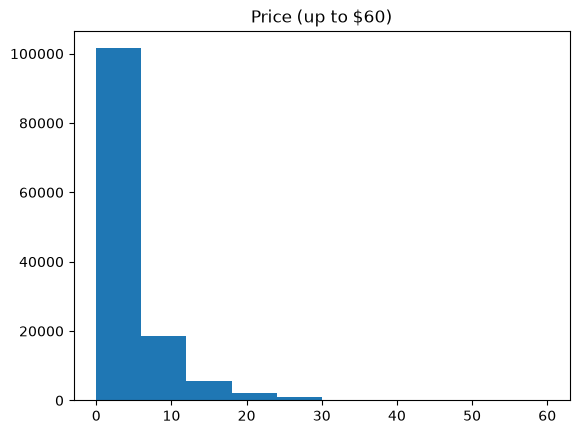

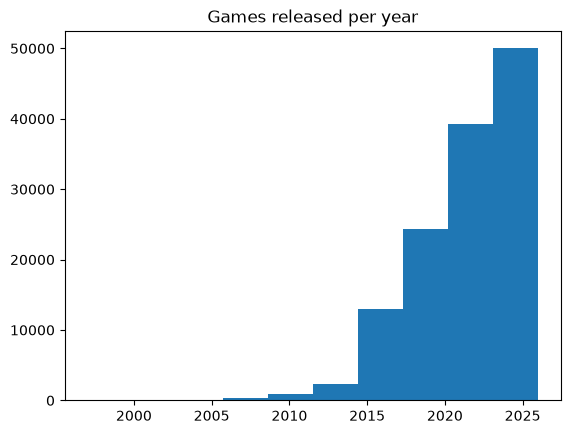

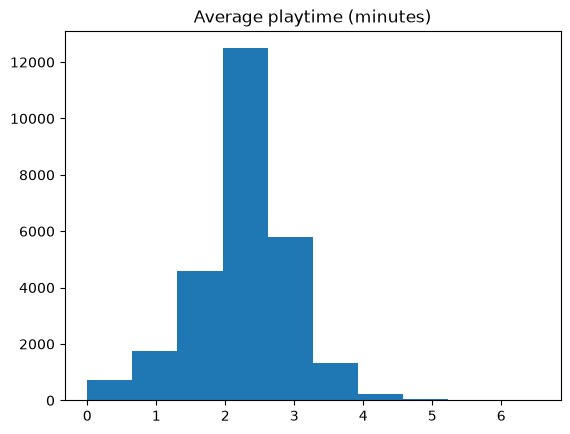

In [40]:
played = df[df[target] > 0]
year = pd.to_datetime(df["Release date"], format="%b %d, %Y", errors="coerce").dt.year

# Histograms
plt.hist(df.loc[df["Price"] <= 60, "Price"])
plt.title("Price (up to $60)")
plt.show()

plt.hist(year.dropna())
plt.title("Games released per year")
plt.show()

plt.hist(np.log10(played[target]))
plt.title("Average playtime (minutes)")
plt.show()


## Cleaning the Data

In [41]:
data = df.copy()

# Dropping Data
data = data.drop(columns = ["Reviews", "Metacritic url", "AppID", "Screenshots", "Movies", "Categories", "Notes", "Windows", "Linux", "Mac", "Discount", "DLC count", "About the game", "Supported languages", "Full audio languages", "Header image", "Website", "Support url", "Support email", "User score", "Positive", "Negative", "Score rank"])
data = data.drop(data[data['Average playtime forever'] <= 0].index)

df.replace([""], np.nan, inplace=True)
data.dropna(axis=0, inplace=True)
print("Number of Missing Values in Each Column:")
print(data.isna().sum())

print(data.shape)
data.head(30)


Number of Missing Values in Each Column:
Name                          0
Release date                  0
Estimated owners              0
Peak CCU                      0
Required age                  0
Price                         0
Metacritic score              0
Achievements                  0
Recommendations               0
Average playtime forever      0
Average playtime two weeks    0
Median playtime forever       0
Median playtime two weeks     0
Developers                    0
Publishers                    0
Genres                        0
Tags                          0
dtype: int64
(24569, 17)


,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Metacritic score,Achievements,Recommendations,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Genres,Tags
1,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,0,0,231,8,0,8,0,minori,MangaGamer,Adventure,"Adventure,Visual Novel,Anime,Cute"
6,Armored Brigade II,"Apr 8, 2025",0 - 20000,8,0,35.99,0,0,107,675,0,1253,0,Veitikka Studios,Matrix Games,"Simulation,Strategy","Simulation,Strategy,RTS,Wargame,Grand Strategy..."
12,Fantasy General II,"Sep 5, 2019",100000 - 200000,13,0,13.99,80,77,994,489,0,52,0,Owned by Gravity,Slitherine Ltd.,Strategy,"Strategy,Turn-Based Strategy,Fantasy,Turn-Base..."
17,Redline,"Oct 23, 2014",0 - 20000,0,0,1.04,0,0,0,203,0,203,0,"Accolade, Inc.","Atari,Nightdive Studios","Action,Racing","Action,Racing,Gore,Violent,FPS,Classic,Post-ap..."
21,Evertried,"Oct 21, 2021",0 - 20000,0,0,5.99,0,66,0,480,0,480,0,Lunic Games / Danilo Domingues,DANGEN Entertainment,"Indie,Strategy","Strategy,Rogue-like,Mystery Dungeon,Rogue-lite..."
26,Bad North: Jotunn Edition,"Nov 16, 2018",500000 - 1000000,64,0,2.99,0,11,11250,342,86,173,139,"Plausible Concept,Oskar Stålberg",Raw Fury,"Action,Indie,Simulation","Wargame,Vikings,Tower Defense,Real Time Tactic..."
27,Lucky Night: Texas Hold'em VR,"Jul 26, 2017",100000 - 200000,0,0,0.00,0,0,0,111,0,121,0,ATC Games,ATC Games,"Casual,Free To Play","Free to Play,Casual,VR"
34,Epic Arena,"May 5, 2015",100000 - 200000,2,0,0.00,0,45,0,88,0,93,0,Shadow Masters,Shadow Masters,"Free To Play,Indie,Strategy","Free to Play,Strategy,Indie,Turn-Based,Turn-Ba..."
41,MazeBot,"May 3, 2018",0 - 20000,0,0,0.00,0,9,0,220,0,220,0,Dynamite Whale,Dynamite Whale,"Action,Casual,Indie","Indie,Action,Casual,Quick-Time Events,Retro"
42,The Metronomicon: Slay The Dance Floor,"Sep 29, 2016",20000 - 50000,1,0,4.99,79,32,277,183,0,237,0,Puuba,Akupara Games,"Action,Indie,RPG","Rhythm,Music,Indie,Soundtrack,Singleplayer,RPG..."


## Fixing Inconsistent Labels

In [42]:
# Genres mixes real genres with other labels
genre_counts = data["Genres"].str.split(",").explode().replace("", np.nan).dropna().value_counts()
print(genre_counts.head(15).to_string())

Genres
Indie                    16375
Action                   10662
Adventure                10219
Casual                    7839
Simulation                5905
Strategy                  5580
RPG                       5473
Early Access              1545
Free To Play              1488
Sports                    1056
Racing                     868
Massively Multiplayer      695
Utilities                  225
Design & Illustration      153
Violent                    144


## Getting Rid of Outliers

In [43]:
print(len(data))

24569


In [44]:

cut = data[target].quantile(0.999)

# Gets rid of "Aartform Curvy 3D 3.0" $299,
# "Houdini Indie" $269,
# "Hexaluga Dungeons and Hunting" $199,
# and "MaJiang" $160

data = data[(data["Price"] <= 100) & (data[target] <= cut)].copy()


## Removing Duplicates

I dropped AppID earlier, so a game that is listed twice under different AppIDs now shows up as two identical rows. I removed those so the same game is not counted twice in the analysis.

In [45]:
print("Duplicate rows:", data.duplicated().sum())
data = data.drop_duplicates()
print(data.shape)

Duplicate rows: 756
(23784, 17)


## Q1: Which genres/tags lead to the highest playtimes (all time)?

For this part, I decided to use decision tree reg. Avg playtime is a number (so this is regression), and I used a decision tree because it was demonstrated in class and seemed like a good option, considering the relationship is unlikely to be any sort of straight line/direct correlation. The inputs for this are Price, Achievements, Release Year, and 10 genres 

Baseline R2: -0.0
Tree R2:     0.136


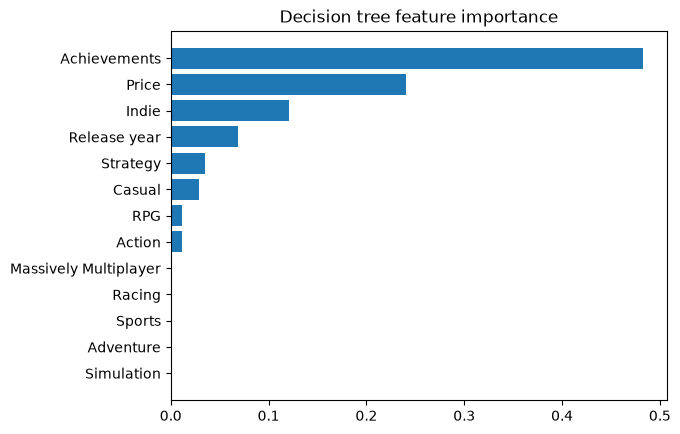

In [46]:
from sklearn.tree import DecisionTreeRegressor

CORE_GENRES = ["Action", "Adventure", "Casual", "Indie", "Simulation", "Strategy",
               "RPG", "Sports", "Racing", "Massively Multiplayer"]

# inputs: price, achievements, release year, and the 10 genres as 0/1 columns
release_year = pd.to_datetime(data["Release date"], format="%b %d, %Y").dt.year
genre_flags = data["Genres"].str.get_dummies(sep=",")[CORE_GENRES]
X = pd.concat([data[["Price", "Achievements"]], release_year.rename("Release year"), genre_flags], axis=1)
y = np.log1p(data[target])      # log because playtime is very skewed

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
tree = DecisionTreeRegressor(max_depth=5, min_samples_leaf=50, random_state=42).fit(X_train, y_train)

print("Baseline R2:", round(r2_score(y_test, np.full(len(y_test), y_train.mean())), 3))
print("Tree R2:    ", round(r2_score(y_test, tree.predict(X_test)), 3))

importance = pd.Series(tree.feature_importances_, index=X.columns).sort_values()
plt.barh(importance.index, importance.values)
plt.title("Decision tree feature importance")
plt.show()

The tree gets an R squared of about 0.14 on the test games, so it explains a small part of playtime. It relies most on Achievements (48%) and Price (24%), then the Indie genre (12%) and release year (7%). Feature importance only really specifies what inputs matter, not which genres have the highest playtime, so I also compared median playtime for each genre and tag below.

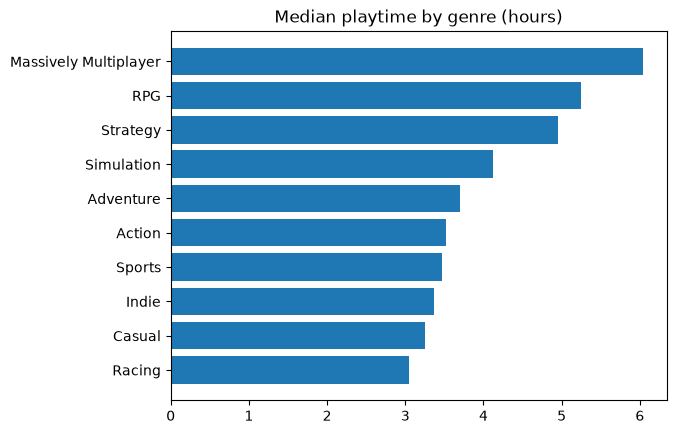

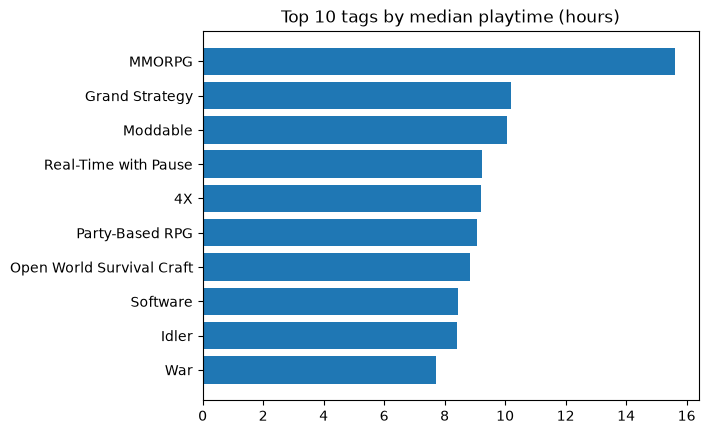

In [47]:
hours = data[target] / 60

# one row per (game, genre) and per (game, tag)
g = pd.DataFrame({"genre": data["Genres"].str.split(","), "hours": hours}).explode("genre")
genre_med = g[g["genre"].isin(CORE_GENRES)].groupby("genre")["hours"].median().sort_values()

t = pd.DataFrame({"tag": data["Tags"].str.split(","), "hours": hours}).explode("tag")
t["tag"] = t["tag"].str.strip()
tag_stats = t.groupby("tag")["hours"].agg(["median", "count"])
tag_med = tag_stats[tag_stats["count"] >= 200]["median"].sort_values()    # only tags with 200+ games

plt.barh(genre_med.index, genre_med.values)
plt.title("Median playtime by genre (hours)")
plt.show()

plt.barh(tag_med.tail(10).index, tag_med.tail(10).values)
plt.title("Top 10 tags by median playtime (hours)")
plt.show()

**Takeaway:** For genres, Massively Multiplayer (6.0 hours), RPG (5.3), and Strategy (5.0) have the highest median playtimes, and Racing (3.1) and Casual (3.3) are the lowest. Tags separate games more than genres do (only tags with 200+ games are shown): MMORPG (15.6 hours), Grand Strategy (10.2), and Moddable (10.1) are on top, and 4X and Real-Time with Pause (9.2 each) are at the bottom. Games with a lot of content or replay value have the longest playtimes.

## Q2: Can we predict a game's average playtime forever based on price factors?

For this one, I used linreg. Average playtime is a number, and I wanted to see how much it goes up or down with each change in price and achievements, which the regression numbers show. I used Price and Achievements as the price factors and logged both (and the playtime) because they are pretty skewed. I also compared it to a baseline that always guesses the average playtime.

Baseline R2:          -0.0
Linear regression R2: 0.077
Typical error (MAE, log scale): 1.09
Price coefficient: 0.347 | Achievements coefficient: 0.157


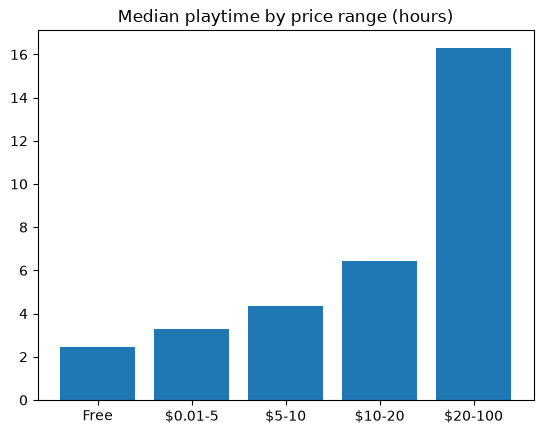

In [48]:
# price factors: price and achievements (logged because both are very skewed)
X2 = np.log1p(data[["Price", "Achievements"]])
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.2, random_state=42)

lin = LinearRegression().fit(X2_train, y2_train)
pred = lin.predict(X2_test)

print("Baseline R2:         ", round(r2_score(y2_test, np.full(len(y2_test), y2_train.mean())), 3))
print("Linear regression R2:", round(r2_score(y2_test, pred), 3))
print("Typical error (MAE, log scale):", round(mean_absolute_error(y2_test, pred), 2))
print("Price coefficient:", round(lin.coef_[0], 3), "| Achievements coefficient:", round(lin.coef_[1], 3))

# median playtime by price range
bands = pd.cut(data["Price"], [-0.01, 0, 5, 10, 20, 100], labels=["Free", "$0.01-5", "$5-10", "$10-20", "$20-100"])
price_med = hours.groupby(bands, observed=True).median()

plt.bar(price_med.index.astype(str), price_med.values)
plt.title("Median playtime by price range (hours)")
plt.show()

**Takeaway:** Price and achievements together only explain around 8% of the variation in playtime (R² = 0.077, the baseline is 0). However, the direction is pretty clear: the price coefficient (0.35) is bigger than the achievements one (0.16), and median playtime climbs with price, from 2.4 hours for free games to 16.3 hours for $20-$100 games. More expensive games get played longer, but price alone is not enough to predict playtime.

## Q3: Can we cluster games into distinct playtime archetypes based on playtime and peak concurrent users?

I used K-means clustering because we don't have labels for game "types" and want the data to group itself. K-means works with distances, so I took the log of both columns (they are very skewed and Peak CCU is 0 for many games) and scaled them so neither one dominates. I compared different numbers of clusters with the silhouette score (higher means the clusters are more clearly separated).

In [49]:
# NOTE: for this section, I had some AI assistance. I believed that the K-means method would be the best pick, but I didn't really remember/know how to fully build this up myself.

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# log both columns (log1p handles Peak CCU = 0), then put them on the same scale
Z = StandardScaler().fit_transform(np.log1p(data[[target, "Peak CCU"]]))

for k in range(2, 7):
    labels_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Z)
    print(f"k = {k}: silhouette = {silhouette_score(Z, labels_k, sample_size=5000, random_state=42):.3f}")

k = 2: silhouette = 0.503
k = 3: silhouette = 0.459
k = 4: silhouette = 0.440
k = 5: silhouette = 0.410
k = 6: silhouette = 0.398


   games  median playtime (hours)  median peak CCU
0   4436                     0.35              0.0
1  11789                     3.37              0.0
2   5449                     8.02             12.0
3   2110                    25.37            278.5


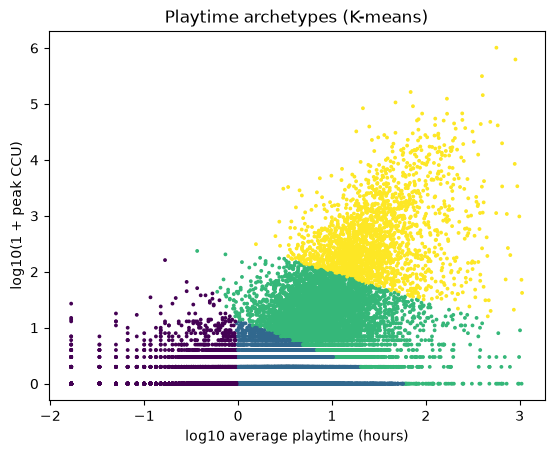

In [50]:
K = 4
labels = pd.Series(KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(Z), index=data.index)

cluster_summary = pd.DataFrame({
    "games": labels.value_counts(),
    "median playtime (hours)": hours.groupby(labels).median(),
    "median peak CCU": data["Peak CCU"].groupby(labels).median(),
}).sort_values("median playtime (hours)")
print(cluster_summary.round(2))

plt.scatter(np.log10(hours), np.log10(data["Peak CCU"] + 1), c=labels, s=3)
plt.title("Playtime archetypes (K-means)")
plt.xlabel("log10 average playtime (hours)")
plt.ylabel("log10(1 + peak CCU)")
plt.show()

**Why 4 was chosen for k:** the silhouette score is highest at k = 2 (0.50), but that only splits games into "low" and "active". The score falls slowly (0.44 at k = 4), and k = 4 splits the active games into "steady" and "hit" groups, which fits a question about archetypes better.

**Takeaway:** four archetypes:
- **Barely played (4,436 games):** about 21 minutes of playtime with hardly any concurrent players.
- **Typical quiet games (11,789 games):** about 3.4 hours, with a peak CCU of 0 for a lot of them.
- **Steady small audiences (5,449 games):** about 8 hours and a median peak of 12 players.
- **Hits (2,110 games):** about 25 hours and a median peak of about 279 players.

Playtime and peak CCU rise together. Many played games (about 44%) have a recorded peak CCU of 0, which limits how much this column can tell us.

## Saving the results for the dashboard

In [51]:
# ".to_csv" spam
data.to_csv("data/games_clean.csv", index=False)
genre_med.to_csv("data/genre_playtime.csv")
tag_med.to_csv("data/tag_playtime.csv")
price_med.to_csv("data/price_playtime.csv")
cluster_summary.to_csv("data/cluster_summary.csv")